# Stationarity in Time Series

This notebook accompanies the note [stationarity](../../notes/time_series/stationarity.md). Weak stationarity asks for a constant mean, a constant finite variance, and an autocovariance $\gamma(h)$ that depends only on the lag. We simulate the processes from the note and check each claim numerically:

1. the worked AR(1) example $X_t = 1 + 0.8X_{t-1} + \varepsilon_t$ (mean 5, variance 2.778, $\gamma(1)=2.222$);
2. stationary, unit-root, and explosive behavior;
3. the random walk, whose variance grows as $t\sigma^2$, and its differencing;
4. deterministic versus stochastic trends and what ADF/KPSS say about them;
5. rolling moments as a local-stationarity check.

## 1. The worked AR(1) example

For $X_t = 1 + 0.8X_{t-1} + \varepsilon_t$ with $\mathrm{Var}(\varepsilon_t)=1$ the note derives

$$\mu = \frac{1}{1-0.8} = 5, \qquad \gamma(0)=\frac{1}{1-0.8^2}\approx 2.778, \qquad \gamma(1)=0.8\,\gamma(0)\approx 2.222, \qquad \rho(1)=0.8.$$

We simulate a long path (after a burn-in) and compare sample moments with these values.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss, acf

rng = np.random.default_rng(42)

def simulate_ar1(c, phi, n, rng, burn=500, x0=0.0):
    eps = rng.normal(0.0, 1.0, n + burn)
    x = np.empty(n + burn)
    x[0] = x0
    for t in range(1, n + burn):
        x[t] = c + phi * x[t - 1] + eps[t]
    return x[burn:]

x = simulate_ar1(1.0, 0.8, 200_000, rng)
mu_hat = x.mean()
g0_hat = x.var()
g1_hat = np.mean((x[1:] - mu_hat) * (x[:-1] - mu_hat))

print(f"mean      : theory 5.0000   sample {mu_hat:.4f}")
print(f"gamma(0)  : theory {1/(1-0.8**2):.4f}   sample {g0_hat:.4f}")
print(f"gamma(1)  : theory {0.8/(1-0.8**2):.4f}   sample {g1_hat:.4f}")
print(f"rho(1)    : theory 0.8000   sample {g1_hat/g0_hat:.4f}")

# Same moments in the first and second half: the distribution is stable over time
h = len(x) // 2
print("\nfirst half  mean/var:", round(x[:h].mean(), 3), round(x[:h].var(), 3))
print("second half mean/var:", round(x[h:].mean(), 3), round(x[h:].var(), 3))

mean      : theory 5.0000   sample 4.9959
gamma(0)  : theory 2.7778   sample 2.7880
gamma(1)  : theory 2.2222   sample 2.2291
rho(1)    : theory 0.8000   sample 0.7996

first half  mean/var: 4.979 2.79
second half mean/var: 5.013 2.785


The sample moments match the closed-form values, and the two halves of the record have the same mean and variance, which is exactly what weak stationarity promises. Note that $\rho(1)=0.8$ means consecutive values are strongly related even though the marginal distribution never changes.

## 2. Stationary, unit-root, and explosive cases

The calculation needs $|\phi|<1$. At $\phi=1$ the process sits on the unit-root boundary and its variance does not settle; for $|\phi|>1$ deviations grow. We drive three AR(1) processes with the **same** shocks.

stationary  phi=0.8: range = [   -3.4,     5.2],  std of last 50 values = 1.32
unit root   phi=1.0: range = [   -1.4,    16.8],  std of last 50 values = 3.08
explosive   phi=1.05: range = [   -0.7, 78134.2],  std of last 50 values = 20151.31


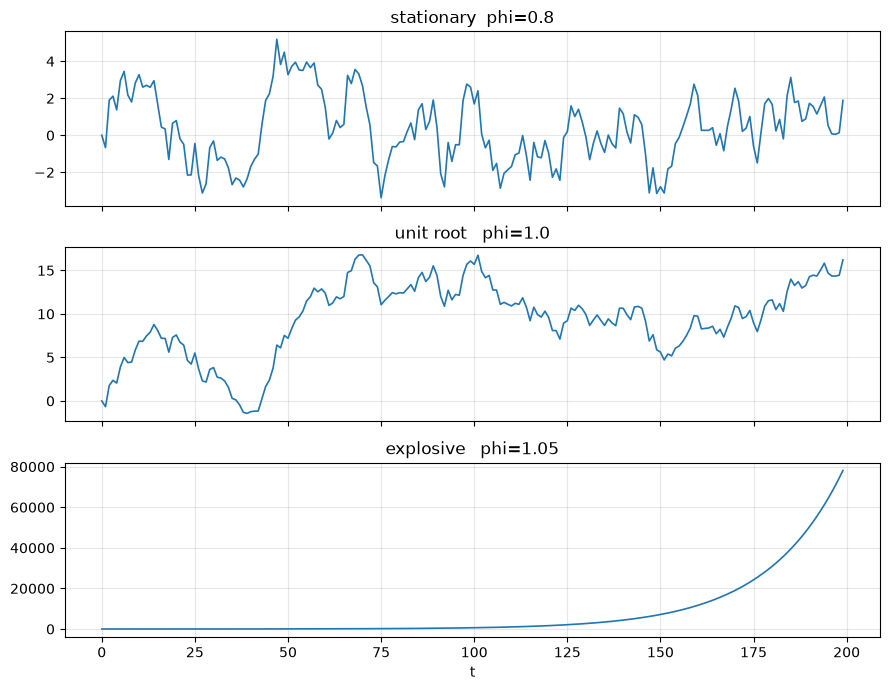

In [2]:
n = 200
eps = rng.normal(0, 1, n)
phis = {"stationary  phi=0.8": 0.8, "unit root   phi=1.0": 1.0, "explosive   phi=1.05": 1.05}

fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
for ax, (label, phi) in zip(axes, phis.items()):
    y = np.zeros(n)
    for t in range(1, n):
        y[t] = phi * y[t - 1] + eps[t]
    ax.plot(y, lw=1.2)
    ax.set_title(label)
    ax.grid(alpha=0.3)
    print(f"{label}: range = [{y.min():7.1f}, {y.max():7.1f}],  std of last 50 values = {y[-50:].std():.2f}")
axes[-1].set_xlabel("t")
plt.tight_layout()
plt.show()

Only the first panel hovers around a fixed level. The unit-root path wanders because every shock is permanent, and the explosive path leaves its starting region at a geometric rate. In a short sample the first two can look alike, which is why plots, root conditions, and tests are used together.

## 3. Random walk: variance grows, differences are white noise

For $X_t = X_{t-1}+\varepsilon_t$ with fixed $X_0$ we have $\mathrm{Var}(X_t\mid X_0)=t\sigma^2$. We check this across many independent paths (an ensemble), then difference one path to recover its shocks.

t= 25: theory t*sigma^2 =   25.0   ensemble variance =   24.77
t=100: theory t*sigma^2 =  100.0   ensemble variance =   98.48
t=400: theory t*sigma^2 =  400.0   ensemble variance =  390.75

max |diff - shock| = 3.164135620181696e-15
lag-1 ACF of the level     : 0.987
lag-1 ACF of the difference: 0.013


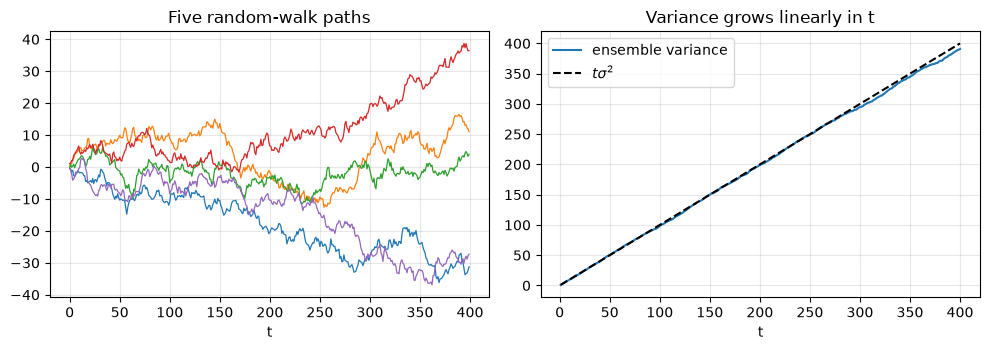

In [3]:
n_paths, n_steps, sigma = 5000, 400, 1.0
shocks = rng.normal(0, sigma, (n_paths, n_steps))
paths = shocks.cumsum(axis=1)              # X_0 = 0
t_grid = np.arange(1, n_steps + 1)
ens_var = paths.var(axis=0)

for t in (25, 100, 400):
    print(f"t={t:3d}: theory t*sigma^2 = {t*sigma**2:6.1f}   ensemble variance = {ens_var[t-1]:7.2f}")

# differencing recovers the innovations exactly
one = paths[0]
d = np.diff(one, prepend=0.0)
print("\nmax |diff - shock| =", np.abs(d - shocks[0]).max())
print("lag-1 ACF of the level     :", round(acf(one, nlags=1)[1], 3))
print("lag-1 ACF of the difference:", round(acf(d, nlags=1)[1], 3))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(paths[:5].T, lw=0.9)
ax[0].set_title("Five random-walk paths")
ax[1].plot(t_grid, ens_var, label="ensemble variance")
ax[1].plot(t_grid, t_grid * sigma**2, "k--", label=r"$t\sigma^2$")
ax[1].set_title("Variance grows linearly in t")
ax[1].legend()
for a in ax:
    a.grid(alpha=0.3)
    a.set_xlabel("t")
plt.tight_layout()
plt.show()

The ensemble variance follows the line $t\sigma^2$, so the level is not weakly stationary even though the shocks have constant variance. Differencing returns the shocks exactly, and the differenced series has no lag-1 autocorrelation (the level's ACF is close to 1).

## 4. Deterministic trend versus stochastic trend

The note contrasts $y_t = 10+0.2t+\varepsilon_t$ (trend-stationary: detrend) with $y_t=y_{t-1}+\varepsilon_t$ (difference-stationary: difference). We apply ADF (null: unit root) and KPSS (null: stationarity) to the raw series and to the appropriately transformed series.

fitted trend: intercept 9.99, slope 0.201  (true 10, 0.2)
trend-stationary, raw (const+trend) ADF p= 0.000 (reject unit root if small)   KPSS p=0.100 (reject stationarity if small; table limits 0.01-0.10)
trend-stationary, detrended (const) ADF p= 0.000 (reject unit root if small)   KPSS p=0.100 (reject stationarity if small; table limits 0.01-0.10)
random walk w/ drift, raw (const+trend) ADF p= 0.066 (reject unit root if small)   KPSS p=0.010 (reject stationarity if small; table limits 0.01-0.10)
random walk w/ drift, differenced (c) ADF p= 0.000 (reject unit root if small)   KPSS p=0.100 (reject stationarity if small; table limits 0.01-0.10)


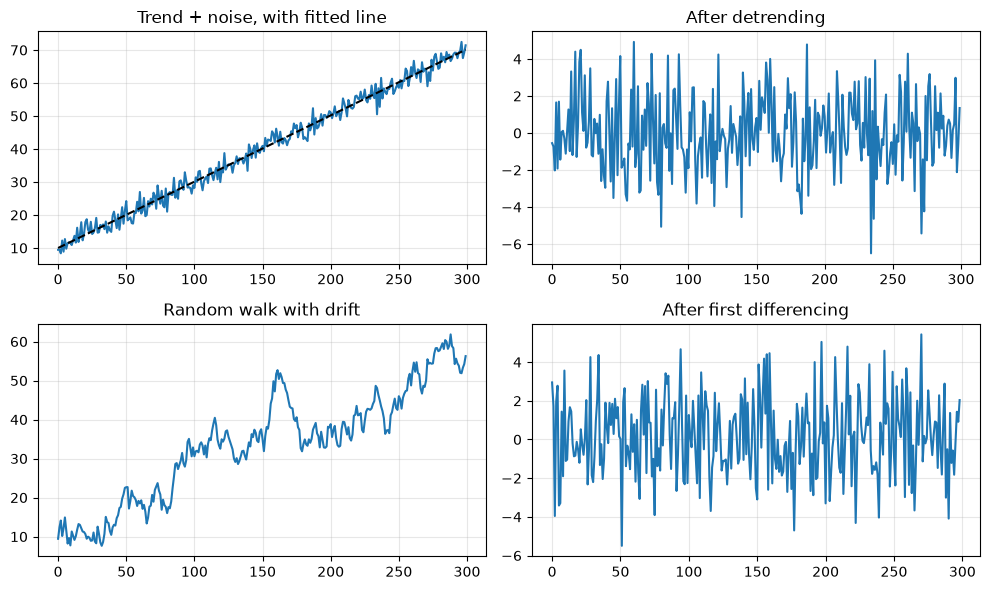

In [4]:
n = 300
tt = np.arange(n)
trend_stat = 10 + 0.2 * tt + rng.normal(0, 2, n)
rw_drift = np.cumsum(rng.normal(0.2, 2, n)) + 10        # stochastic trend with drift

# detrend by least squares
b, a = np.polyfit(tt, trend_stat, 1)
detrended = trend_stat - (a + b * tt)
print(f"fitted trend: intercept {a:.2f}, slope {b:.3f}  (true 10, 0.2)")

def tests(name, y, reg):
    adf_p = adfuller(y, regression=reg, autolag="AIC")[1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kpss_p = kpss(y, regression=reg, nlags="auto")[1]
    print(f"{name:34s} ADF p={adf_p:6.3f} (reject unit root if small)   KPSS p={kpss_p:5.3f} (reject stationarity if small; table limits 0.01-0.10)")

tests("trend-stationary, raw (const+trend)", trend_stat, "ct")
tests("trend-stationary, detrended (const)", detrended, "c")
tests("random walk w/ drift, raw (const+trend)", rw_drift, "ct")
tests("random walk w/ drift, differenced (c)", np.diff(rw_drift), "c")

fig, ax = plt.subplots(2, 2, figsize=(10, 6))
ax[0, 0].plot(trend_stat); ax[0, 0].plot(a + b * tt, "k--"); ax[0, 0].set_title("Trend + noise, with fitted line")
ax[0, 1].plot(detrended); ax[0, 1].set_title("After detrending")
ax[1, 0].plot(rw_drift); ax[1, 0].set_title("Random walk with drift")
ax[1, 1].plot(np.diff(rw_drift)); ax[1, 1].set_title("After first differencing")
for a_ in ax.ravel():
    a_.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Both raw series trend upward, yet they need different treatment. The ADF and KPSS columns should be read together: a small ADF p-value with a large KPSS p-value supports stationarity, and the reverse supports non-stationarity. The tests assess a statistical specification (which deterministic terms were included); they cannot by themselves identify the mechanism.

## 5. Local stationarity: rolling moments

A series can be approximately stationary within a window but not globally. With window $w$,

$$\hat\mu_t = \frac1w\sum_{j=0}^{w-1}y_{t-j}, \qquad \hat\sigma_t^2=\frac1{w-1}\sum_{j=0}^{w-1}(y_{t-j}-\hat\mu_t)^2 .$$

We build a series with a mean shift at $t=300$ and a variance increase at $t=450$, then compare a short and a long window.

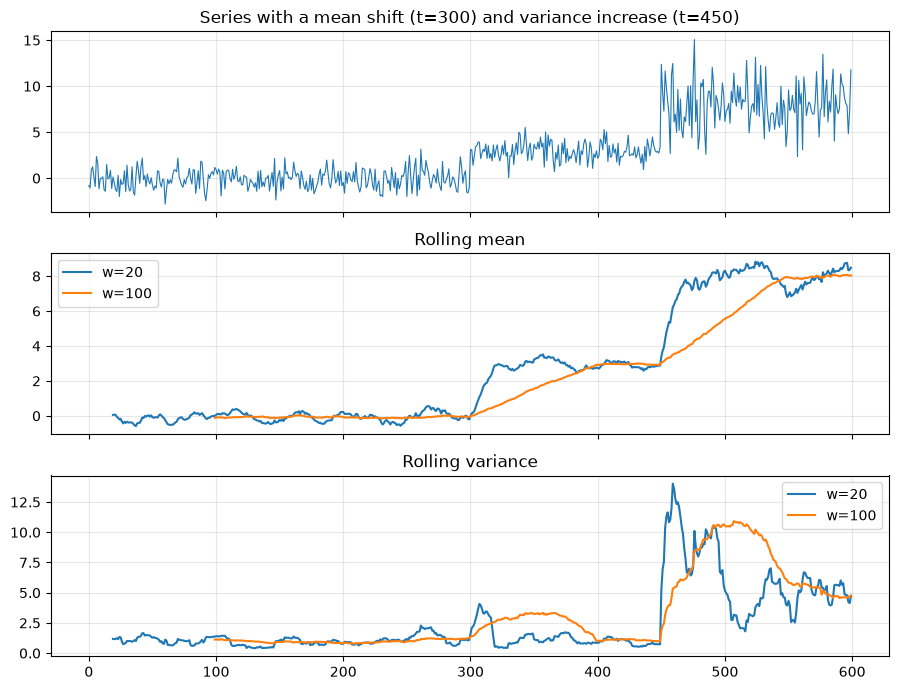

segment means    : [-0.08, 2.94, 8.05]
segment variances: [1.06, 0.95, 5.65]


In [5]:
n = 600
y = rng.normal(0, 1, n)
y[300:] += 3.0           # level shift
y[450:] *= 2.5           # larger spread

def rolling_moments(y, w):
    m = np.full(len(y), np.nan); v = np.full(len(y), np.nan)
    for t in range(w - 1, len(y)):
        win = y[t - w + 1:t + 1]
        m[t], v[t] = win.mean(), win.var(ddof=1)
    return m, v

fig, ax = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
ax[0].plot(y, lw=0.8); ax[0].set_title("Series with a mean shift (t=300) and variance increase (t=450)")
for w in (20, 100):
    m, v = rolling_moments(y, w)
    ax[1].plot(m, label=f"w={w}")
    ax[2].plot(v, label=f"w={w}")
ax[1].set_title("Rolling mean"); ax[2].set_title("Rolling variance")
for a_ in ax:
    a_.grid(alpha=0.3)
ax[1].legend(); ax[2].legend()
plt.tight_layout()
plt.show()

print("segment means    :", [round(float(y[s:e].mean()), 2) for s, e in [(0, 300), (300, 450), (450, 600)]])
print("segment variances:", [round(float(y[s:e].var(ddof=1)), 2) for s, e in [(0, 300), (300, 450), (450, 600)]])

The short window reacts quickly but is noisy, while the long window is smooth and lags behind the changes: the window size is a resolution choice. Both rolling summaries clearly reject a single global mean and variance, which is the visual evidence against weak stationarity for this series.

**Takeaways.** Stationarity is a modeling condition, not a visual impression. Check it with the right transformation (detrend a deterministic trend, difference a stochastic one), inspect rolling moments, and use ADF/KPSS as supporting evidence only.